# Docking analysis


In [1]:
import pandas as pd 
import numpy as np


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df1 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/diffdock_RMSD_Flare_Flare.csv")
df2 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/diffdock_RMSD_Flare_SMILES.csv")
df3 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/diffdock_RMSD_Schroe_Schroe.csv")
df4 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/diffdock_RMSD_Schroe_SMILES.csv")

In [4]:
df4.head(2)

,Protein,Ligand,RMSD_pose0,RMSD_pose1,RMSD_pose2,RMSD_pose3,RMSD_pose4,RMSD_pose5,RMSD_pose6,RMSD_pose7,RMSD_pose8,RMSD_pose9,Min_RMSD,Max_RMSD,Mean_RMSD,Median_RMSD,Best_Pose
0,bcsin_226,BCS-CT37643,5.053676,4.622615,3.199874,4.015014,3.918256,3.921433,4.554426,4.678682,4.674525,5.051745,3.199874,5.053676,4.369025,4.588520,pose2
1,bcsin_233,BCS-CV49374,6.605945,7.765128,7.942375,7.646559,8.054577,5.906592,6.582985,39.594410,6.363336,13.377877,5.906592,39.594410,10.983978,7.705844,pose5


In [5]:
# Combine the DataFrames
data = {
    'Value': pd.concat([df1['Min_RMSD'], df2['Min_RMSD'], df3['Min_RMSD'], df4['Min_RMSD']]),
    'Approach': ['DiffDock (Flare + Flare) '] * len(df1) + ['DiffDock (Flare + SMILES)'] * len(df2) + ['DiffDock (Schroe + Schroe)'] * len(df3) + ['DiffDock (Schroe + SMILES)'] * len(df4)
}

df_diffdock = pd.DataFrame(data)
df_diffdock = df_diffdock.reset_index(drop=True)
df_diffdock = df_diffdock.dropna(subset=['Value'])


In [6]:
df5 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/Flare_Flare_RMSD.csv")
df6 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/Flare_Schroe_RMSD.csv")
df7 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/Schroe_Flare_RMSD.csv")
df8 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/Schroe_Schroe_RMSD.csv")


In [7]:
# Combine the DataFrames
data2 = {
    'Value': pd.concat([df5['Min_RMSD'], df6['Min_RMSD'], df7['Min_RMSD'], df8['Min_RMSD'] ]),
    'Approach': ['Flare (Flare Prep) '] * len(df5) + ['Flare (Schroe Prep)'] * len(df6) + ['Schroe (Flare Prep)'] * len(df7) + ['Schroe (Schroe Prep)'] * len(df8)
}

df_classic = pd.DataFrame(data2)
df_classic = df_classic.reset_index(drop=True)
df_classic = df_classic.dropna(subset=['Value'])

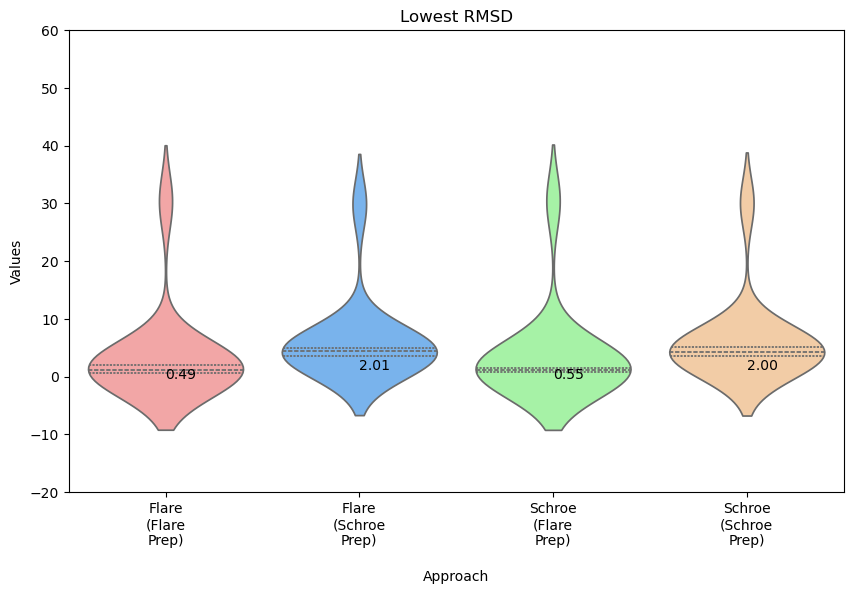

In [10]:
# Create the violin plot with custom colors
plt.figure(figsize=(10, 6))
sns.violinplot(x='Approach', y='Value', hue='Approach', split=False, inner="quart", data=df_classic, palette=['#FF9999', '#66B3FF', '#99FF99', '#FFCC99']) #inner="point"
plt.title('Lowest RMSD')
#plt.xlabel('DataFrame')
plt.ylabel('Values')

# Set y-axis limits
plt.ylim(-20, 60)
# Set x-axis labels with line breaks
plt.xticks(ticks=range(len(df_classic['Approach'].unique())), 
           labels=[label.replace(' ', '\n') for label in df_classic['Approach'].unique()])

#means = combined_df.groupby('Approach')['Value'].mean()
#for i, mean in enumerate(means):
#        plt.text(i, mean +1, f'{mean:.2f}', ha='center', va='bottom', fontsize=10, color='black')

mins = df_classic.groupby('Approach')['Value'].min()
for i, minn in enumerate(mins):
        plt.text(i, minn +1, f'{minn:.2f}', ha='left', va='top', fontsize=10, color='black')

plt.show()

In [11]:
df_all = pd.concat([df_diffdock, df_classic], ignore_index=True)
print(df_diffdock.shape)
print(df_classic.shape)
print(df_all.shape)


(45, 2)
(52, 2)
(97, 2)


/tmp/ipykernel_4217/2495557621.py:3: UserWarning: 
The palette list has fewer values (4) than needed (8) and will cycle, which may produce an uninterpretable plot.
  sns.violinplot(x='Approach', y='Value', hue='Approach', split=False, fill=False, data=df_all, palette=['#036172', '#84b93d', '#009276', '#d4a1f0']) #inner="point"


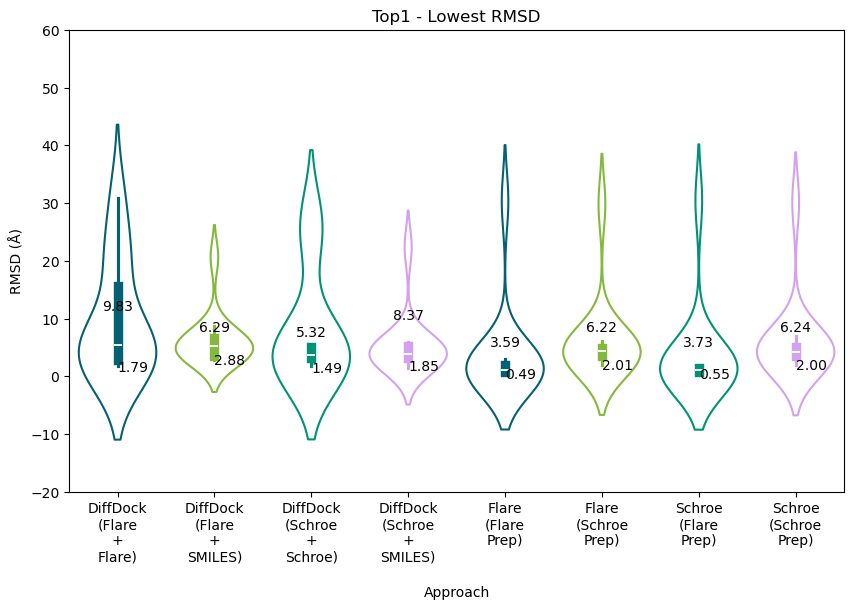

In [12]:
# Create the violin plot with custom colors
plt.figure(figsize=(10, 6))
sns.violinplot(x='Approach', y='Value', hue='Approach', split=False, fill=False, data=df_all, palette=['#036172', '#84b93d', '#009276', '#d4a1f0']) #inner="point"
plt.title('Top1 - Lowest RMSD')
#plt.xlabel('DataFrame')
plt.ylabel('RMSD (Å)')

# Set y-axis limits
plt.ylim(-20, 60)
# Set x-axis labels with line breaks
plt.xticks(ticks=range(len(df_all['Approach'].unique())), 
           labels=[label.replace(' ', '\n') for label in df_all['Approach'].unique()])

means = df_all.groupby('Approach')['Value'].mean()
for i, mean in enumerate(means):
        plt.text(i, mean +1, f'{mean:.2f}', ha='center', va='bottom', fontsize=10, color='black')

mins = df_all.groupby('Approach')['Value'].min()
for i, minn in enumerate(mins):
        plt.text(i, minn +1, f'{minn:.2f}', ha='left', va='top', fontsize=10, color='black')

plt.show()

# add AF 

In [13]:
df9 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/docking/diffdock_RMSD_AF.csv")

In [14]:
# Combine the DataFrames
data3 = {
    'Value': pd.concat([df9['Min_RMSD'], df5['Min_RMSD'], df6['Min_RMSD'], df7['Min_RMSD'], df8['Min_RMSD']]),
    'Approach': ['DiffDock (AF + SMILES)'] * len(df8) + ['Flare (Flare Prep) '] * len(df5) + ['Flare (Schroe Prep)'] * len(df6) + ['Schroe (Flare Prep)'] * len(df7) + ['Schroe (Schroe Prep)'] * len(df8)
}

df_classic = pd.DataFrame(data3)
df_classic = df_classic.reset_index(drop=True)
df_classic = df_classic.dropna(subset=['Value'])

In [18]:
df9['Min_RMSD']

0      6.523571
1      6.700187
2      7.565597
3     19.746258
4     20.097596
5      6.119603
6      5.456322
7     13.965857
8     18.270387
9     12.743605
10    14.798884
11     8.121907
12    15.483741
Name: Min_RMSD, dtype: float64

In [15]:
df_all = pd.concat([df_diffdock, df_classic], ignore_index=True)
print(df_diffdock.shape)
print(df_classic.shape)
print(df_all.shape)


(45, 2)
(65, 2)
(110, 2)


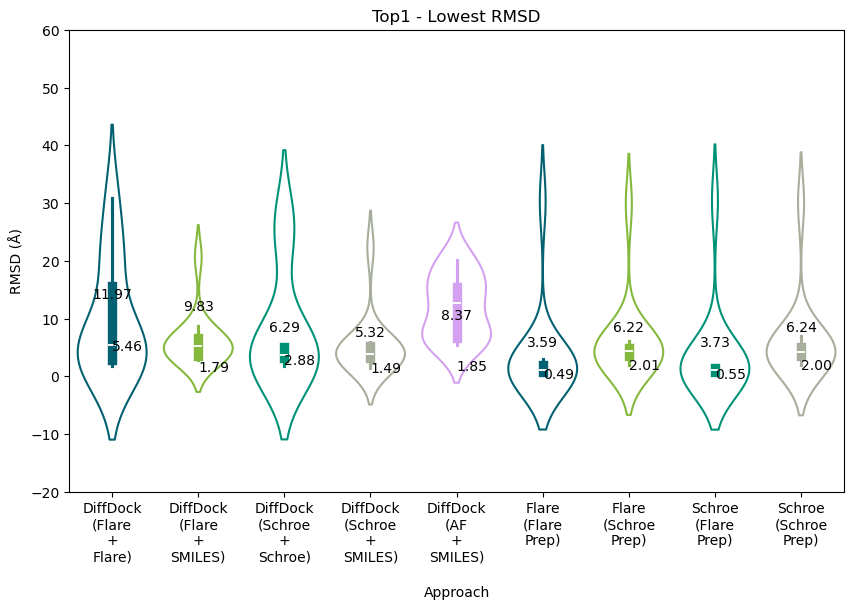

In [24]:
# Create the violin plot with custom colors
plt.figure(figsize=(10, 6))
sns.violinplot(x='Approach', y='Value', hue='Approach', split=False, fill=False, data=df_all, palette=['#036172', '#84b93d', '#009276', '#a7ae9c', '#d4a1f0', '#036172', '#84b93d', '#009276', '#a7ae9c']) #inner="point"
plt.title('Top1 - Lowest RMSD')
#plt.xlabel('DataFrame')
plt.ylabel('RMSD (Å)')

# Set y-axis limits
plt.ylim(-20, 60)
# Set x-axis labels with line breaks
plt.xticks(ticks=range(len(df_all['Approach'].unique())), 
           labels=[label.replace(' ', '\n') for label in df_all['Approach'].unique()])

means = df_all.groupby('Approach')['Value'].mean()
for i, mean in enumerate(means):
        plt.text(i, mean +1, f'{mean:.2f}', ha='center', va='bottom', fontsize=10, color='black')

mins = df_all.groupby('Approach')['Value'].min()
for i, minn in enumerate(mins):
        plt.text(i, minn +1, f'{minn:.2f}', ha='left', va='top', fontsize=10, color='black')

plt.show()